---
tags: [algorithm, optimization, oracle-based]
---

# QSVT Filteringによるグラフ分割問題の求解

本チュートリアルでは、Quantum Singular Value Transform(QSVT)を使って、与えられたハミルトニアンの基底エネルギーを求め、グラフ分割問題を解く方法を説明します。

Lin and Tongの基底エネルギーアルゴリズム{cite:p}`10.48550/arXiv.2002.12508`は、*フィルタリング*によってコストハミルトニアンの最小固有値を求めます。閾値パラメータ$\mu$を1つ決めると、Linear Combination of Unitaries(LCU)によって$H - \mu I$のブロックエンコーディングを構築できます。さらにsign関数のQSVT近似を用いて、閾値パラメータ$\mu$の片側にある固有空間へのprojectorを作ります。post-selectionを通過したショットの割合が、$\mu$をどちらへ動かせばよいかを古典的な二分探索に伝えます。

本チュートリアルでは、この手順をグラフ分割問題に適用し、ブロックエンコーディングの構築、単一の閾値での評価、二分探索による基底エネルギーの推定までを示します。

In [1]:
# Install the latest Qamomile through pip!
# !pip install "qamomile[qiskit]" jijmodeling matplotlib networkx

In [2]:
import jijmodeling as jm
import matplotlib.pyplot as plt
import networkx as nx
import numpy as np

from qamomile.optimization import OMMXProblem, QSVTEigenstateFilterExperiment
from qamomile.qiskit import Aer
from qamomile.stdlib import qsvt, qsvt_filter_projector, synthesize_sign_filter
from qamomile.visualization import draw

SEED = 42

## 問題設定

グラフ分割は、頂点を同じ大きさの2つのグループへ分けながら、切断される辺の数をできるだけ少なくする問題です。ここでは等サイズ制約のもとで切断辺数を最小化します。この制約は`OMMXProblem.from_instance`がペナルティ項として目的関数に取り込みます。

グラフ分割問題そのものの詳細は[QAOAによるグラフ分割](qaoa_graph_partition)を参照してください。

In [3]:
problem = jm.Problem("Graph Partitioning")


@problem.update
def _(problem: jm.DecoratedProblem):
    V = problem.Dim()
    E = problem.Natural(ndim=2)  # edge list: [[u1,v1], [u2,v2], ...]
    x = problem.BinaryVar(shape=(V,))

    # Objective: minimize edges cut between partitions
    problem += (
        E.rows().map(lambda e: x[e[0]] * (1 - x[e[1]]) + x[e[1]] * (1 - x[e[0]])).sum()
    )

    # Constraint: equal partition sizes
    problem += problem.Constraint("Equal Partition", x.sum() == V / 2)


problem

Problem(name="Graph Partitioning", sense=MINIMIZE, objective=sum(E.rows().map(lambda (e: Array[:; natural]): x[e[0]] * (1 - x[e[1]]) + x[e[1]] * (1 - x[e[0]]))), constraints={Equal Partition: [Constraint(name="Equal Partition", sense=EQUAL, left=sum(x), right=V / 2, shape=Scalar(Float)),],})

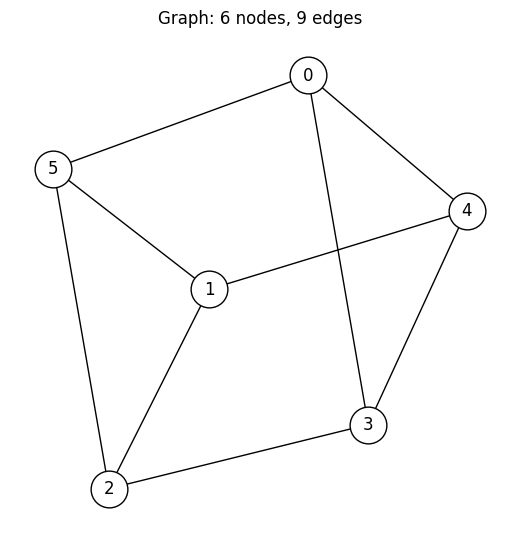

In [4]:
num_nodes = 6
# Triangular prism: the triangles {0, 3, 4} and {1, 2, 5} joined by a perfect
# matching (0-5, 1-4, 2-3). Separating the two triangles cuts only the three
# matching edges; every other equal split breaks a triangle and cuts more, so
# the optimal partition is unique.
edge_list = [
    [0, 3],
    [0, 4],
    [0, 5],
    [1, 2],
    [1, 4],
    [1, 5],
    [2, 3],
    [2, 5],
    [3, 4],
]

G = nx.Graph()
G.add_nodes_from(range(num_nodes))
G.add_edges_from(edge_list)
assert G.number_of_nodes() == num_nodes
assert G.number_of_edges() == len(edge_list)

pos = nx.spring_layout(G, seed=1)
plt.figure(figsize=(5, 5))
nx.draw(G, pos, with_labels=True, node_color="white", node_size=700, edgecolors="black")
plt.title(f"Graph: {G.number_of_nodes()} nodes, {G.number_of_edges()} edges")
plt.show()

In [5]:
instance_data = {"V": num_nodes, "E": edge_list}
instance = problem.eval(instance_data)

## アルゴリズム

イジングコストハミルトニアンを$H$と書き、閾値$\mu$を1つ選びます。アルゴリズムが扱うのはシフトした演算子$H - \mu I$で、その固有値は$E_i - \mu$です。残したい固有状態でちょうど負に、それ以外で正になります。したがって両者を分けるのはsign関数の役目です。

ブロックエンコーディングは、ユニタリでない演算子をより大きなユニタリ$U$の1つのブロックとして埋め込みます。LCUは$H - \mu I$をPauli列の重み付き和として書くことでこれを構築します。その代償が正規化定数$\alpha'$であり、実際にエンコードされるのは正規化された演算子$(H - \mu I) / \alpha'$です。そのスペクトルは$[-1, 1]$に収まります。このブロックは、ancillaレジスタ、すなわち*signal*レジスタがすべて0と測定されることで選択されます。

続いてQSVTは、エンコードされた演算子に多項式の応答を作用させます。位相$\Phi$が与えられると、次の交替列を適用し、

$$R(\phi_0),\; U,\; R(\phi_1),\; U^\dagger,\; \dots$$

複素応答を得ます。補助量子ビットを1つ使ってその実部を取り出すと、$p\!\left((H - \mu I)/\alpha'\right)$を実現できます。ここで$p$としてsign関数の近似を選べば、

$$p\!\left(\frac{H - \mu I}{\alpha'}\right) \approx
\operatorname{sign}\!\left(\frac{H - \mu I}{\alpha'}\right),$$

理想的なsign関数の極限では、このブロックは*鏡映*$R$になります。すなわち$\mu$より下の固有空間には$-1$として、上の固有空間には$+1$として作用します。有限次数では近似であり、滑らかなフィルタになります。

鏡映はまだprojectorではありませんが、$P_\mu = (I - R)/2$はprojectorであり、Hadamard testによって確率的に実現できます。実装では実部を取り出す量子ビットとは別にprobe量子ビットを1つ使うため、入力のブロックエンコーディングに合計2つの補助量子ビットを追加します。一様重ね合わせ$|\varphi_0\rangle = H^{\otimes n}|0\rangle$から出発したとき、すべてのancillaが0と測定されるショットの割合は次の量を推定します。

$$P(\mu)=\lVert P_\mu |\varphi_0\rangle \rVert^2 \approx \frac{\#\{i : E_i < \mu\}}{2^n},$$

理想的なsignフィルタの極限では、これは$\mu$より下にあるスペクトルの割合です。この値を、古典的な二分探索で探索方向を決める判定条件として用います。$|\varphi_0\rangle$のなかで$\mu$より下の固有状態が重みを持つときに限り、この値は0から離れた値をとります。

探索そのものはLin and TongのAlgorithm 1{cite:p}`10.48550/arXiv.2002.12508`です。固有値は$[c-\alpha, c+\alpha)$に存在します。ここで$\alpha$は$H$単体の正規化定数、$c$はその定数項です。ある閾値$\mu$を基底エネルギー$\lambda_0$と比較して考えます。$\mu$が$[c-\alpha, \lambda_0)$にあるときは固有値がすべて除かれ、$P(\mu)=0$となります。区間$[\lambda_0,\lambda_1)$では基底の固有空間だけが残り、縮退度を$d$として$\gamma^2 = d/2^n$を与えます。$\lambda_1$より上では確率は増える一方です。したがって探索は$[c-\alpha,c+\alpha)$を間隔$h$のグリッドに分割し、$P(\mu)$が$\tau = \gamma^2/2$を超えるかどうかで進む方向を決めます。

成否を分ける入力が2つあります。$\gamma$は初期状態の重なりの下界ですが事前には分からないため、仮定して与えるしかありません。また$h$は(これも未知の)スペクトルギャップより小さくとる必要があります。最後に、近似誤差によって推定した$P(\mu)$が単調でなくなる場合があります。そのため探索は1点だけを信用せず、連続する2つのグリッド点$(B_k, B_{k+1})$を*組*にして評価します。

## Qamomileによる実装

Qamomileは、上で説明した固有状態フィルタリングのアルゴリズムを`qamomile.optimization.qsvt_eigenstate_filter`の`QSVTEigenstateFilterExperiment`として提供しています。`OMMXProblem.from_instance`で問題インスタンスをモデルに変換し、元の制約ペナルティを保持します。`synthesize_sign_filter`でフィルタを合成します。実験は問題ハミルトニアンのブロックエンコーディングの構築、probe回路の組み立て、そして測定サンプルのpost-selectionとデコードまでを行うため、手順全体を問題インスタンスから実行できます。以下ではまずこれを使って閾値を1つ試し、次に実験が組み立てる構成要素を順に見て、最後に二分探索を実行します。

ただし内部のパラメータの多くが解の品質を左右するため、以下ではそれぞれのパラメータと選び方を説明します。

イジングハミルトニアンの定数項はブロックエンコーディングから除いてあります。この手法の性能は正規化定数$\alpha$に依存しており、恒等演算子の項はこの値を大きくしてしまうためです。一方で定数のオフセットはすべての固有値を等しくずらすだけなので、どの状態が最良かは変わりません。`normalization`($\alpha$)と`energy_offset`($c$)の2つが揃ってスペクトルの範囲を与え、閾値はこの区間のなかから選ぶことになります。

In [6]:
optimization_problem = OMMXProblem.from_instance(instance)
model = optimization_problem.model
spin = model.to_ising()
energy_offset = float(spin.constant)
normalization = sum(abs(coeff) for coeff in spin.coefficients.values())
# One seeded backend for every circuit on this page, so the printed numbers are
# reproducible from one run to the next.
backend = Aer(seed_transpiler=SEED)

low = energy_offset - normalization
high = energy_offset + normalization
print(f"alpha={normalization}  offset={energy_offset}")
print(f"every eigenvalue lies in [{low}, {high}]")

# Reference spectrum: the Ising operator is diagonal, so we can read the exact
# energies off directly and check the search against them later.
# !!! This is only a check and the computation takes exponential time in general.
energies = np.full(1 << spin.num_variables, float(spin.constant))
for state in range(energies.size):
    for word, coeff in spin.coefficients.items():
        parity = sum((state >> i) & 1 for i in word) & 1
        energies[state] += coeff * (-1.0 if parity else 1.0)

ground_energy = float(energies.min())
degeneracy = int((energies == ground_energy).sum())
print(f"levels={np.unique(energies)}  ground={ground_energy} ({degeneracy}-fold)")

assert low <= energies.min() and energies.max() <= high

alpha=3.0  offset=6.0
every eigenvalue lies in [3.0, 9.0]
levels=[3. 5. 7. 9.]  ground=3.0 (2-fold)


### 閾値を1つ試す

`QSVTEigenstateFilterExperiment`は$\mu$を回路に埋め込むため、閾値ごとに個別のコンパイルが必要です。正の`scale`で合成したフィルタは$\mu$より下の固有空間を残します。これは最小固有値(基底エネルギー)を探索したい場合に必要な向きです。

`degree`と`delta`は対で決まります。`delta`は多項式の遷移領域の幅を定め、`degree`はChebyshev展開の次数で、その遷移を表現できるだけ大きくとる必要があります。

:::{note}
指定しない場合、`degree`と`delta`には実験がデフォルト値を設定します。
:::

分解能は次の式で与えられます。

$$
\Delta = \frac{\min_i |E_i-\mu|}{\alpha + |\mu - c|}
$$

ここで$E_i$は固有値で、その他のパラメータはこれまでに定義したものです。分解能を知るには基底エネルギーを事前に知っている必要がある、という状況がしばしば起こります。実際には分解能を上回るように、値を推測するか上界を見積もることになります。`degree`はおおよそ$O(1/\Delta)$で増えます。

以下では$\mu=4$としてアルゴリズムを実演します。このとき上回るべき分解能は$\Delta = \frac{|4-3|}{3 + |4 - 6|} = 1/5$であり、`delta=8`とすれば遷移領域の幅がこのギャップに合い、`degree=21`でそれを表現できます。対の取り方を誤っても精度が静かに落ちるわけではなく、$|p| \le 1$のチェックによってその場で棄却されます。

各閾値での測定は8,000回にします。探索では$\mu=3.5$も調べますが、そのときの有限次数の多項式による成功確率は約$0.02198$で、判定境界$\tau=0.015625$に近いためです。2,000回の測定では、回路が意図した多項式を正しく実装していても、測定のばらつきによってこの境界を下回ることがあります。測定回数を増やせば、多項式や後述する2点ずつの探索手順を変えずに、そのリスクを減らせます。

In [7]:
DEGREE, DELTA = 21, 8
SHOTS = 8000
probe_polynomial = synthesize_sign_filter(degree=DEGREE, delta=DELTA)
print(
    f"probe filter: degree={DEGREE}, delta={DELTA} -> {len(probe_polynomial.phases.phases)} phases"
)


def probe(mu, shots=SHOTS):
    """Estimate the fraction of the spectrum below `mu`."""
    experiment = QSVTEigenstateFilterExperiment(
        model, mu=mu, polynomial=probe_polynomial
    )
    return experiment.run(on=backend, shots=shots, seed=SEED).success_probability


# Two of the 64 states sit at the ground energy, so the predicate saturates at
# 2 / 64 once mu clears it.
sampled_p4 = probe(4.0)
exact_p4 = float((energies < 4.0).mean())
print(f"p(mu=4.0) = {sampled_p4:.4f}   (exact: {exact_p4:.4f})")

# Six standard deviations of shot noise, plus a small allowance for the blur of
# a finite-degree sign approximation.
shot_noise = 6.0 * np.sqrt(exact_p4 * (1.0 - exact_p4) / SHOTS)
assert abs(sampled_p4 - exact_p4) < shot_noise + 0.01

probe filter: degree=21, delta=8 -> 22 phases


p(mu=4.0) = 0.0310   (exact: 0.0312)


パラメータから定まる多項式近似に対応する位相因子の計算には、外部ライブラリの`pyqsp`を使っています。Rust側が位相列の応答を独立に計算し、実装される実多項式と目標多項式の誤差を検証します。この検証が保証するのは多項式の実装誤差であり、不連続なsign関数に対する近似誤差ではありません。

実験はprojectorの量子回路を構築します。その回路を`run`で実行し、結果の`success_probability`から成功確率を求めます。(上の厳密計算は精度を確認するための参照値です)

### 構成要素

実験は3つの回路を入れ子に合成します。その順に描画すると、ブロックエンコーディングがどのようにprojectorへ変わっていくかが分かります。

図を読みやすく保つため、位相ベクトルは4要素に短くしてあります(上で使った22要素ではありません)。
最初は実装内部のループを折りたたんで表示します。図の操作欄からループの本体を表示したり、回路を展開したりできます。

In [8]:
DRAW_MU = 4.0

# Four phases instead of the 22 the degree-21 filter uses; only the count
# affects the circuit's shape, not the values.
phi_demo = [0.1, 0.2, 0.3, 0.4]
drawing_experiment = QSVTEigenstateFilterExperiment(model, mu=DRAW_MU, phases=phi_demo)
# The public descriptor is the same one used to build the executable probe.
shifted = drawing_experiment.shifted_encoding
n_signal = shifted.signal_width
n_system = shifted.system_width

print(f"alpha' = {shifted.normalization}   signal={n_signal}  system={n_system}")

alpha' = 5.0   signal=3  system=6


#### 1. ブロックエンコーディング $U$

イジングハミルトニアンはユニタリの線形結合として書かれ、$\operatorname{PREPARE}$、$\operatorname{SELECT}$、$\operatorname{PREPARE}^\dagger$として実現されます。$\operatorname{PREPARE}$は係数の振幅をsignalレジスタに載せ、$\operatorname{SELECT}$はsignalの状態に応じて対応するPauli-$Z$項をsystemに作用させ、$\operatorname{PREPARE}^\dagger$がそれをuncomputeします。

得られるのは、左上のブロック、つまりsignalレジスタがすべて0と測定される部分が$(H - \mu I)/\alpha'$となるようなユニタリです。そのブロックの外側は利用できないため、すべてのショットをそこでpost-selectする必要があります。

In [9]:
draw(shifted.unitary, inline_depth=0, loops="folded")

Diagram(display=Display(entrypoint='qamomile.stdlib.lcu.encoded__e930c1df66a0', values=(DisplayValue(id=0, label='state', type_label='Q[Bits[9]]', quantum=True, stage='Value', width=9), DisplayValue(id=1, label='reshape', type_label='tuple[Q[Bits[3]], Q[Bits[6]]]', quantum=True, stage='Value', width=9), DisplayValue(id=2, label='signal', type_label='Q[Bits[3]]', quantum=True, stage='Value', width=3), DisplayValue(id=3, label='system', type_label='Q[Bits[6]]', quantum=True, stage='Value', width=6), DisplayValue(id=4, label='call', type_label='Q[Bits[3]]', quantum=True, stage='Value', width=3), DisplayValue(id=5, label='select_call', type_label='tuple[Q[Bits[3]], Q[Bits[6]]]', quantum=True, stage='Value', width=9), DisplayValue(id=6, label='signal', type_label='Q[Bits[3]]', quantum=True, stage='Value', width=3), DisplayValue(id=7, label='system', type_label='Q[Bits[6]]', quantum=True, stage='Value', width=6), DisplayValue(id=8, label='adjoint_call', type_label='Q[Bits[3]]', quantum=True, stage='Value', width=3), DisplayValue(id=9, label='tuple', type_label='tuple[Q[Bits[3]], Q[Bits[6]]]', quantum=True, stage='Value', width=9), DisplayValue(id=10, label='reshape', type_label='Q[Bits[9]]', quantum=True, stage='Value', width=9)), inputs=(0,), nodes=(DisplayNode(kind='structure', opcode='qcore.reshape', label='reinterpret / split / concatenate', inputs=(0,), outputs=(1,), children=(), line=199), DisplayNode(kind='structure', opcode='qcore.unpack', label='unpack', inputs=(1,), outputs=(2, 3), children=(), line=199), DisplayNode(kind='call', opcode='qcore.call', label='encode__4a4610f33ba8', inputs=(2,), outputs=(4,), children=(), line=200), DisplayNode(kind='call', opcode='qcore.select_call', label='select_call ', inputs=(4, 3), outputs=(5,), children=(), line=201), DisplayNode(kind='structure', opcode='qcore.unpack', label='unpack', inputs=(5,), outputs=(6, 7), children=(), line=201), DisplayNode(kind='call', opcode='qcore.adjoint_call', label='adjoint_call qamomile.stdlib.lcu.encode__4a4610f33ba8', inputs=(6,), outputs=(8,), children=(), line=202), DisplayNode(kind='structure', opcode='qcore.tuple', label='pack', inputs=(8, 7), outputs=(9,), children=(), line=203), DisplayNode(kind='structure', opcode='qcore.reshape', label='reinterpret / split / concatenate', inputs=(9,), outputs=(10,), children=(), line=203), DisplayNode(kind='exit', opcode='return', label='return', inputs=(10,), outputs=(), children=(), line=203))), loops='folded', classical='expressions', wires='registers')

#### 2. QSVTの交替列

ブロックエンコーディングが与えられると、`qsvt`は次を適用します。

$$R(\phi_0),\; U,\; R(\phi_1),\; U^\dagger,\; R(\phi_2),\; U,\; \dots$$

ここで$U$は上で構築したブロックエンコーディング、$R(\phi) = e^{i\phi(2\Pi - I)}$であり、$\Pi$はsignalレジスタをすべて0の状態へ射影します。この一連の列は`qsvt`が担当します。$U$と$U^\dagger$を交互に並べ、位相を適用します。

その効果は、encodeされた演算子に複素多項式の応答を作用させることです。`pyqsp`が生成した位相を使い、補助量子ビットで実部を取り出すと、この実多項式は$\mathrm{sign}$を近似するため、良いブロックは$\mu$の片側の固有空間に関する鏡映を近似します。

In [10]:
draw(qsvt(shifted, phases=phi_demo), inline_depth=0, loops="folded")

Diagram(display=Display(entrypoint='qamomile.stdlib.qsvt.transform__ee247c4d65f9', values=(DisplayValue(id=0, label='state', type_label='Q[Bits[9]]', quantum=True, stage='Value', width=9), DisplayValue(id=1, label='0.1', type_label='Real', quantum=False, stage='Value', width=None), DisplayValue(id=2, label='call', type_label='Q[Bits[9]]', quantum=True, stage='Value', width=9), DisplayValue(id=3, label='true', type_label='Bool', quantum=False, stage='Value', width=None), DisplayValue(id=4, label='0.2', type_label='Real', quantum=False, stage='Value', width=None), DisplayValue(id=5, label='tuple', type_label='tuple[Bool, Real]', quantum=False, stage='Value', width=None), DisplayValue(id=6, label='false', type_label='Bool', quantum=False, stage='Value', width=None), DisplayValue(id=7, label='0.3', type_label='Real', quantum=False, stage='Value', width=None), DisplayValue(id=8, label='tuple', type_label='tuple[Bool, Real]', quantum=False, stage='Value', width=None), DisplayValue(id=9, label='true', type_label='Bool', quantum=False, stage='Value', width=None), DisplayValue(id=10, label='0.4', type_label='Real', quantum=False, stage='Value', width=None), DisplayValue(id=11, label='tuple', type_label='tuple[Bool, Real]', quantum=False, stage='Value', width=None), DisplayValue(id=12, label='tuple', type_label='tuple[tuple[Bool, Real], tuple[Bool, Real], tuple[Bool, Real]]', quantum=False, stage='Value', width=None), DisplayValue(id=13, label='0', type_label='Int', quantum=False, stage='Value', width=None), DisplayValue(id=14, label='3', type_label='Int', quantum=False, stage='Value', width=None), DisplayValue(id=15, label='1', type_label='Int', quantum=False, stage='Value', width=None), DisplayValue(id=16, label='state', type_label='Q[Bits[9]]', quantum=True, stage='Value', width=9), DisplayValue(id=17, label='\x00iterable:0:12', type_label='tuple[tuple[Bool, Real], tuple[Bool, Real], tuple[Bool, Real]]', quantum=False, stage='Value', width=None)), inputs=(0,), nodes=(DisplayNode(kind='classical', opcode='qcore.constant', label='0.1', inputs=(), outputs=(1,), children=(), line=236), DisplayNode(kind='call', opcode='qcore.call', label='rotate__7098ba15d294', inputs=(0, 1), outputs=(2,), children=(), line=236), DisplayNode(kind='classical', opcode='qcore.constant', label='true', inputs=(), outputs=(3,), children=(), line=237), DisplayNode(kind='classical', opcode='qcore.constant', label='0.2', inputs=(), outputs=(4,), children=(), line=237), DisplayNode(kind='structure', opcode='qcore.tuple', label='pack', inputs=(3, 4), outputs=(5,), children=(), line=237), DisplayNode(kind='classical', opcode='qcore.constant', label='false', inputs=(), outputs=(6,), children=(), line=237), DisplayNode(kind='classical', opcode='qcore.constant', label='0.3', inputs=(), outputs=(7,), children=(), line=237), DisplayNode(kind='structure', opcode='qcore.tuple', label='pack', inputs=(6, 7), outputs=(8,), children=(), line=237), DisplayNode(kind='classical', opcode='qcore.constant', label='true', inputs=(), outputs=(9,), children=(), line=237), DisplayNode(kind='classical', opcode='qcore.constant', label='0.4', inputs=(), outputs=(10,), children=(), line=237), DisplayNode(kind='structure', opcode='qcore.tuple', label='pack', inputs=(9, 10), outputs=(11,), children=(), line=237), DisplayNode(kind='structure', opcode='qcore.tuple', label='pack', inputs=(5, 8, 11), outputs=(12,), children=(), line=237), DisplayNode(kind='classical', opcode='qcore.constant', label='0', inputs=(), outputs=(13,), children=(), line=237), DisplayNode(kind='classical', opcode='qcore.constant', label='3', inputs=(), outputs=(14,), children=(), line=237), DisplayNode(kind='classical', opcode='qcore.constant', label='1', inputs=(), outputs=(15,), children=(), line=237), DisplayNode(kind='loop', opcode='qcore.for', label='for step in range(0, 3, 1)', inputs=(13, 14, 15, 2, 12), outputs=(16, 17), children=(), line=237), DisplayNode(kind='exit', opcode='return', label='return', inputs=(16,)

#### 3. Lin & Tongのprojector

目標は、この鏡映を射影$P_\mu = (I - R)/2$に変えることです。しかしこのprojectorは**ユニタリではない**ため、回路でそのまま適用することはできません。

鍵になるのは、恒等演算子とQSVTの応答を干渉させる点です。そのためHadamard testを使えば確率的に実現できます。まず補助量子ビットを1つ使ってQSVT応答の実部$p$を取り出し、もう1つの*probe量子ビット*で恒等演算子の分岐とその実応答の分岐をコヒーレントに選択させます。probe量子ビットを重ね合わせにし、その制御のもとで実応答を作用させ、2つ目のHadamardで2つの分岐を干渉させます。入力のsignalレジスタに加えて、この2つの補助量子ビットが0と測定されれば、$(I-p)/2$が作用した分岐であることが分かります。このアルゴリズムに成功確率という概念があるのはそのためであり、post-selectionを**すべての補助量子ビット**に対して行う理由もここにあります。

In [11]:
projector = qsvt_filter_projector(shifted, phases=phi_demo)
draw(projector.unitary, inline_depth=0, loops="folded")

Diagram(display=Display(entrypoint='qamomile.stdlib.qsvt_eigenstate_filter.projector__0b07c3c67b19', values=(DisplayValue(id=0, label='state', type_label='Q[Bits[11]]', quantum=True, stage='Value', width=11), DisplayValue(id=1, label='reshape', type_label='tuple[Q[Bits[1]], Q[Bits[10]]]', quantum=True, stage='Value', width=11), DisplayValue(id=2, label='probe', type_label='Q[Bits[1]]', quantum=True, stage='Value', width=1), DisplayValue(id=3, label='workspace', type_label='Q[Bits[10]]', quantum=True, stage='Value', width=10), DisplayValue(id=4, label='h', type_label='Q[Bits[1]]', quantum=True, stage='Value', width=1), DisplayValue(id=5, label='z', type_label='Q[Bits[1]]', quantum=True, stage='Value', width=1), DisplayValue(id=6, label='control_call', type_label='tuple[Q[Bits[1]], Q[Bits[10]]]', quantum=True, stage='Value', width=11), DisplayValue(id=7, label='probe', type_label='Q[Bits[1]]', quantum=True, stage='Value', width=1), DisplayValue(id=8, label='workspace', type_label='Q[Bits[10]]', quantum=True, stage='Value', width=10), DisplayValue(id=9, label='h', type_label='Q[Bits[1]]', quantum=True, stage='Value', width=1), DisplayValue(id=10, label='tuple', type_label='tuple[Q[Bits[1]], Q[Bits[10]]]', quantum=True, stage='Value', width=11), DisplayValue(id=11, label='reshape', type_label='Q[Bits[11]]', quantum=True, stage='Value', width=11)), inputs=(0,), nodes=(DisplayNode(kind='structure', opcode='qcore.reshape', label='reinterpret / split / concatenate', inputs=(0,), outputs=(1,), children=(), line=300), DisplayNode(kind='structure', opcode='qcore.unpack', label='unpack', inputs=(1,), outputs=(2, 3), children=(), line=300), DisplayNode(kind='quantum', opcode='quantum.h', label='h(probe)', inputs=(2,), outputs=(4,), children=(), line=301), DisplayNode(kind='quantum', opcode='quantum.z', label='z(h)', inputs=(4,), outputs=(5,), children=(), line=302), DisplayNode(kind='call', opcode='qcore.control_call', label='control_call qamomile.stdlib.qsvt_eigenstate_filter.encoded__6c05279e68b9', inputs=(5, 3), outputs=(6,), children=(), line=303), DisplayNode(kind='structure', opcode='qcore.unpack', label='unpack', inputs=(6,), outputs=(7, 8), children=(), line=303), DisplayNode(kind='quantum', opcode='quantum.h', label='h(probe)', inputs=(7,), outputs=(9,), children=(), line=304), DisplayNode(kind='structure', opcode='qcore.tuple', label='pack', inputs=(9, 8), outputs=(10,), children=(), line=305), DisplayNode(kind='structure', opcode='qcore.reshape', label='reinterpret / split / concatenate', inputs=(10,), outputs=(11,), children=(), line=305), DisplayNode(kind='exit', opcode='return', label='return', inputs=(11,), outputs=(), children=(), line=305))), loops='folded', classical='expressions', wires='registers')

### 二分探索

ここまでで、古典的な探索に必要なものは判定条件だけになりました。`B(k)`は「グリッド点$x_k$が残すべき固有空間を捉えている」という1ビットで、ループはアルゴリズムの節で述べたとおり、このビットを連続する2つずつ組にして消費します。

In [12]:
def binary_search_ground_energy(success_prob, low, high, gamma, h=1.0):
    """Algorithm 1 of Lin & Tong: paired (B_k, B_k+1) probes.

    Grid x_k = low + (k + 0.5) * h: the half-cell offset keeps thresholds
    between candidate energies, since the strict comparison in the predicate
    would read zero on a threshold sitting exactly on an eigenvalue. B_k = 1
    iff the estimated probability exceeds tau = gamma**2 / 2.

    The paired-probe loop narrows to at most four cells; a linear scan over
    those finishes the job, so the returned bracket is one cell wide.
    Returns (x_L, x_U) with x_L <= lambda_0 <= x_U -- closed on the left so a
    ground energy sitting exactly on `low` is still bracketed.
    """
    n_grid = int(round((high - low) / h))
    grid = [low + (k + 0.5) * h for k in range(n_grid)]
    tau = 0.5 * gamma**2
    cache = {}

    def B(k):
        # Boundary sentinels: B_-1 = 0 (nothing below), B_G = 1 (all below).
        if not 0 <= k < n_grid:
            return 0 if k < 0 else 1
        if k not in cache:
            cache[k] = success_prob(grid[k])
        return int(cache[k] > tau)

    L, U = 0, n_grid - 1
    print(f"grid {grid[0]:+.2f}..{grid[-1]:+.2f}  G={n_grid}  h={h}  tau={tau:.4f}")

    while U - L > 3:
        k = (L + U) // 2
        bk, bk1 = B(k), B(k + 1)
        print(
            f"  k={k}: B({grid[k]:+.2f})={bk}  B({grid[k + 1]:+.2f})={bk1}",
            end="  ->  ",
        )
        if bk == 1 and bk1 == 1:  # lambda_0 < x_k+1
            U = k + 1
            print(f"(1,1) U<-{U}  [{grid[L]:+.2f}, {grid[U]:+.2f}]")
        elif bk == 0 and bk1 == 0:  # lambda_0 > x_k
            L = k
            print(f"(0,0) L<-{L}  [{grid[L]:+.2f}, {grid[U]:+.2f}]")
        elif bk == 0 and bk1 == 1:  # x_k-1 < lambda_0 < x_k+2
            L, U = max(k - 1, 0), min(k + 2, n_grid - 1)
            print(f"(0,1) -> [{grid[L]:+.2f}, {grid[U]:+.2f}]")
            break
        else:  # x_k < lambda_0 < x_k+1
            L, U = k, k + 1
            print(f"(1,0) -> [{grid[L]:+.2f}, {grid[U]:+.2f}]")
            break

    # Tighten to a single cell: the first grid point whose predicate fires is
    # the smallest threshold that still sees the ground eigenspace. Clamping to
    # the spectrum bound keeps the bracket physical -- no probe is needed below
    # `low`, because no eigenvalue can be there.
    for k in range(L, U + 1):
        if B(k):
            print(f"  refine: first B=1 at k={k} ({grid[k]:+.2f})")
            return max(grid[k] - h, low), grid[k]
    return grid[U], min(grid[U] + h, high)

## 結果

探索を実行すると、基底エネルギーの位置を一切教えないままその範囲を絞り込めます。得られた閾値をフィルタに戻して与えれば基底状態そのものが準備でき、そこからサンプリングすることで分割が復元されます。

In [13]:
gamma = np.sqrt(degeneracy / energies.size)
x_lower, x_upper = binary_search_ground_energy(probe, low, high, gamma=gamma, h=1.0)

print(
    f"\nlambda_0 in [{x_lower:+.2f}, {x_upper:+.2f}]   true lambda_0 = {ground_energy:+.2f}"
)
assert x_lower <= ground_energy <= x_upper

grid +3.50..+8.50  G=6  h=1.0  tau=0.0156


  k=2: B(+5.50)=1  B(+6.50)=1  ->  (1,1) U<-3  [+3.50, +6.50]


  refine: first B=1 at k=0 (+3.50)

lambda_0 in [+3.00, +3.50]   true lambda_0 = +3.00


:::{note}
二分探索で$P(\mu)>\tau$を判定するだけならフィルタがぼやけていても許容できるため、どの評価でも`degree=21`で十分でした。一方、基底の固有空間*だけ*を残そうとすると、$\mu = 3.5$では最適な分解能が探索時の$0.20$ではなく$\Delta = 0.09$になるため、最後のデコードではより鋭い多項式を使います。`degree`だけを上げても遷移が鋭くなるとは限りません。多項式が有界であり、必要なギャップを区別できるよう、`degree`と`delta`を組み合わせて選びます。観測される基底状態の割合は多項式の応答と測定のばらつきにも依存するため、以下で明示的に確認します。
:::

In [14]:
# The predicate needed degree 21; extracting the state itself needs a sharper
# filter at the same threshold.
DECODE_DEGREE, DECODE_DELTA = 41, 11
decode_polynomial = synthesize_sign_filter(degree=DECODE_DEGREE, delta=DECODE_DELTA)
print(
    f"decode filter: degree={DECODE_DEGREE}, delta={DECODE_DELTA} -> {len(decode_polynomial.phases.phases)} phases"
)

decode_experiment = QSVTEigenstateFilterExperiment(
    model, mu=x_upper, polynomial=decode_polynomial
)
run = decode_experiment.run(on=backend, shots=20000, seed=SEED)
result = run.execution.result
sampleset = run.samples
assert sampleset is not None

kept = sampleset.total_occurrences
optimal = sum(
    sample.occurrences
    for sample in sampleset.samples
    if np.isclose(sample.energy, ground_energy)
)
print(f"kept {kept} of {result.shots} shots, {optimal / kept:.1%} at the ground energy")

best = max(sampleset.samples, key=lambda sample: sample.occurrences).values
side = sorted(v for v, bit in best.items() if bit == 1)
cut = sum(1 for u, v in edge_list if best[u] != best[v])
print(f"most sampled partition: {side} | cut={cut}")

assert optimal / kept > 0.85
assert cut == 3 and len(side) == num_nodes // 2

decode filter: degree=41, delta=11 -> 42 phases


kept 510 of 20000 shots, 100.0% at the ground energy
most sampled partition: [0, 3, 4] | cut=3


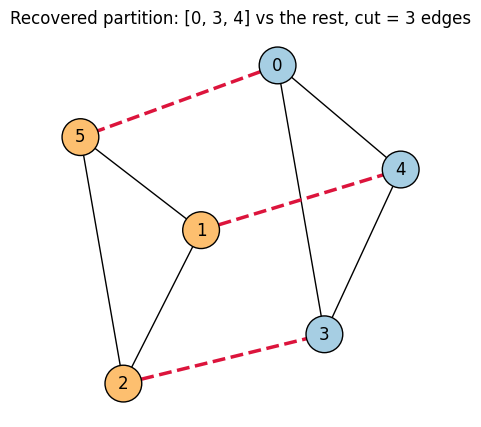

In [15]:
# Draw the recovered partition on the same layout as the input graph: node
# colour is the side, and the cut edges are the objective being minimised.
cut_edges = [(u, v) for u, v in G.edges() if best[u] != best[v]]
kept_edges = [(u, v) for u, v in G.edges() if best[u] == best[v]]

plt.figure(figsize=(5, 5))
nx.draw_networkx_edges(G, pos, edgelist=kept_edges, edge_color="black", width=1.0)
nx.draw_networkx_edges(
    G, pos, edgelist=cut_edges, edge_color="crimson", width=2.5, style="dashed"
)
nx.draw_networkx_nodes(
    G,
    pos,
    node_color=["#a6cee3" if best[v] == 1 else "#fdbf6f" for v in G.nodes()],
    node_size=700,
    edgecolors="black",
)
nx.draw_networkx_labels(G, pos)
plt.title(f"Recovered partition: {side} vs the rest, cut = {cut} edges")
plt.axis("off")
plt.show()

2つの三角形$\{0,3,4\}$と$\{1,2,5\}$は同じ分割を表すため、実行ごとにどちらが最上位に来ることもあります。対応する目的関数値(最小カット)は$3$です。

## まとめ

本notebookでは次のことを行いました。

- `QSVTEigenstateFilterExperiment`を使ってグラフ分割問題のインスタンスをend-to-endで解き、三角柱グラフの一意な最適分割を復元しました。
- このアルゴリズムが確率的である理由を確認しました。$P_\mu = (I - R)/2$はユニタリではないためHadamard testで実現され、すべてのショットをprobe、実部を取り出す量子ビット、元のsignalレジスタでpost-selectする必要があります。
- すべてのパラメータが、正規化されたギャップ$\Delta = \min_i |E_i - \mu| / \alpha'$という1つの数値に帰着することを見ました。イジングの定数項をブロックエンコーディングから除くことが重要なのも、`normalization`と`energy_offset`が対で報告されるのも、このためです。